
Dataset: LMO
Detections: 1442
Mean GT rank: 11.14 / 128
Median GT rank: 4
Top-  1:  20.74% (random:   0.78%)
Top-  5:  62.76% (random:   3.91%)
Top- 10:  80.17% (random:   7.81%)
Top- 25:  89.88% (random:  19.53%)
Top- 50:  93.76% (random:  39.06%)
Top-128: 100.00% (random: 100.00%)

Dataset: YCBV
Detections: 4107
Mean GT rank: 9.89 / 128
Median GT rank: 6
Top-  1:  14.56% (random:   0.78%)
Top-  5:  46.94% (random:   3.91%)
Top- 10:  70.22% (random:   7.81%)
Top- 25:  92.33% (random:  19.53%)
Top- 50:  97.98% (random:  39.06%)
Top-128: 100.00% (random: 100.00%)


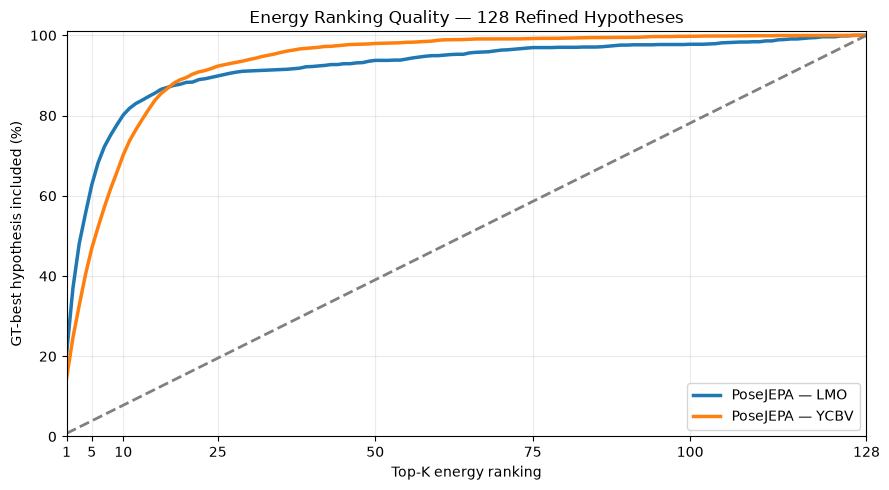

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === CONFIG ===
csv_paths = {
    "LMO": "/experiments/riccardop02/Inference/2026-11-07_16-04-06_lmo_allpose_gt_simple/energy_lmo-test_gt_diagnostics.csv",
    "YCBV": "/experiments/riccardop02/Inference/2026-11-09_09-07-38_ycbv_allpose_gt_simple/energy_ycbv-test_gt_diagnostics.csv"
}

N = 128
K = np.arange(1, N + 1)

# Baseline: ordinamento completamente casuale
random_baseline = K / N * 100

# === PLOT ===
plt.figure(figsize=(9, 5))

for name, csv_path in csv_paths.items():

    # Load
    df = pd.read_csv(csv_path)
    ranks = df["gt_rank_l1_finale"].dropna().to_numpy(dtype=int)

    # Percentuale di casi in cui la migliore posa GT è nella Top-K energetica
    recall = np.array([np.mean(ranks <= k) * 100 for k in K])

    plt.plot(K, recall, linewidth=2.5, label=f"PoseJEPA — {name}")

    # === STATISTICS ===
    print(f"\n{'='*40}")
    print(f"Dataset: {name}")
    print(f"Detections: {len(ranks)}")
    print(f"Mean GT rank: {ranks.mean():.2f} / {N}")
    print(f"Median GT rank: {np.median(ranks):.0f}")

    for k in [1, 5, 10, 25, 50, 128]:
        print(
            f"Top-{k:3d}: {np.mean(ranks <= k)*100:6.2f}% "
            f"(random: {k/N*100:6.2f}%)"
        )

# Random baseline
plt.plot(
    K, random_baseline,
    "--", color="gray", linewidth=2,
)

plt.xlabel("Top-K energy ranking")
plt.ylabel("GT-best hypothesis included (%)")
plt.title("Energy Ranking Quality — 128 Refined Hypotheses")

plt.xlim(1, N)
plt.ylim(0, 101)
plt.xticks([1, 5, 10, 25, 50, 75, 100, 128])
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

# 1. Carica il file CSV (sostituisci 'dati.csv' con il nome reale del tuo file)
df = pd.read_csv('/experiments/riccardop02/Inference/2026-10-28_09-37-44_ycbv_gt_det/energy_ycbv-test_timings.csv')

# 2. Calcola la media della colonna 'detection_time'
media_tempo = df['detection_time'].mean()

# 3. Mostra il risultato
print(f"La media del tempo di detection è: {media_tempo:.6f} secondi")

La media del tempo di detection è: 0.729161 secondi


In [3]:

from pathlib import Path
import pandas as pd

# ============================================================
# INPUT: cartelle da analizzare
# ============================================================

folders = [
    "/experiments/riccardop02/Inference/2026-11-11_13-45-45_lmo_energy_refSTEP3_GT",
    "/experiments/riccardop02/Inference/2026-11-11_14-16-34_ycbv_energy_refSTEP3_GT",
    "/experiments/riccardop02/Inference/2026-11-11_14-33-15_icbin_energy_refSTEP3_GT",
    "/experiments/riccardop02/Inference/2026-11-11_14-39-40_tudl_energy_refSTEP3_GT",
    "/experiments/riccardop02/Inference/2026-11-11_15-27-11_tless_energy_refSTEP3_GT"
]

# ============================================================
# CALCOLO TEMPI
# ============================================================

results = []

for folder in folders:
    folder = Path(folder)

    timing_files = sorted(folder.glob("*test*.csv"))

    if not timing_files:
        print(f"[WARNING] Nessun file timings.csv in {folder.name}")
        continue

    for timing_file in timing_files:
        df = pd.read_csv(timing_file)

        required = {"scene_id", "im_id", "time"}
        if not required.issubset(df.columns):
            print(f"[WARNING] Colonne mancanti in {timing_file}")
            continue

        # Somma dei tempi delle detection per ogni immagine
        per_img = (
            df.groupby(["scene_id", "im_id"])["time"]
              .sum()
              .reset_index(name="image_time")
        )

        # Rimuove la prima detection per confronto no warm-up
        df_nw = df.iloc[1:]
        per_img_nw = (
            df_nw.groupby(["scene_id", "im_id"])["time"]
                 .sum()
        )

        results.append({
            "Folder": folder.name,
            "File": timing_file.name,
            "Images": len(per_img),
            "Detections": len(df),
            "Det/Img": len(df) / len(per_img),
            "Mean Det (s)": df["time"].mean(),
            "Mean Img (s)": per_img["image_time"].mean(),
            "Mean Img NW (s)": per_img_nw.mean(),
            "Median Det (s)": df["time"].median(),
        })

# ============================================================
# TABELLA FINALE
# ============================================================

if results:
    summary = pd.DataFrame(results)

    print("\n========== BOP TIMING SUMMARY ==========\n")
    print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

    print("\n========== SOLO TEMPI MEDI BOP ==========\n")
    BOP_Average = 0
    for _, row in summary.iterrows():
        print(f"{row['Folder']}: {row['Mean Img (s)']:.3f} s")
        BOP_Average += row['Mean Img (s)']
    # Opzionale: salva riepilogo
    # summary.to_csv("bop_timing_summary.csv", index=False)

    print(f"\n\n BOP TIME: {BOP_Average/5}")
else:
    print("Nessun timing valido trovato.")



========== BOP TIMING SUMMARY ==========

                                      Folder                             File  Images  Detections  Det/Img  Mean Det (s)  Mean Img (s)  Mean Img NW (s)  Median Det (s)
  2026-11-11_13-45-45_lmo_energy_refSTEP3_GT              energy_lmo-test.csv     200        1442    7.210         3.090        22.282           22.253           2.959
 2026-11-11_14-16-34_ycbv_energy_refSTEP3_GT             energy_ycbv-test.csv     900        4107    4.563         2.015         9.194            9.190           2.108
2026-11-11_14-33-15_icbin_energy_refSTEP3_GT            energy_icbin-test.csv     150        1786   11.907         6.525        77.690           77.625           7.198
 2026-11-11_14-39-40_tudl_energy_refSTEP3_GT             energy_tudl-test.csv     600         600    1.000         0.426         0.426            0.423           0.423
2026-11-11_15-27-11_tless_energy_refSTEP3_GT energy_tless-test_primesense.csv    1000        6423    6.423         3.